# Is Osero making money?

**An on-chain reconstruction, from two anchors to a basis-point answer.**

Osero is a *Star* in the Sky ecosystem: it draws USDS against a Sky credit line, deploys it into a
yield strategy, and owes Sky a **base rate = SSR + 20 bps**, charged only on the portion actually
borrowed downstream.

Three things make this hard, and they are the whole exercise:

1. **No contract reports the answer.** The stability fee on the ilk is zero — the obligation is
   commercial, not an on-chain accrual. You compute it or it doesn't exist.
2. **We get two anchors and nothing else.** Venue, vault, buffer, rates and position history all have
   to be found.
3. **Every input moves.** SSR is governance-set, utilization drifts block to block, the position gets
   topped up and rebalanced.

**Short version:** Osero borrows from Sky at SSR + 20 bps and lends into SparkLend — also Sky — at a
supply rate below that base. It is **losing ~25 bps**, structurally.

---

This is the terse version of [`DISCOVERY.org`](DISCOVERY.org); same code, less prose. It re-derives
every number from scratch with only `requests` + `matplotlib` — no web3, no eth-abi, no Foundry — so
it can be checked against `discovery/` (Python hypotheses) and `osero-indexer/` (Rust daemon) without
sharing code with either.

**To run:** put an archive-capable mainnet RPC in `.env` at the repo root as `ETH_RPC_URL=...`.
Outputs below are from a live run at block **25,715,376**; re-running produces fresh numbers.

A note on method: free-tier RPCs throttle `eth_getLogs` hard, so wherever a log scan could be replaced
by archive `eth_call` bisection, it has been (Steps 4 and 6). The whole notebook makes **3** log calls,
all single-block.

## Setup

### Keccak-256

Python's `hashlib.sha3_256` is *not* Keccak-256 — different padding. We need it for function
selectors and event topics, so here it is in 30 lines. That keeps the whole notebook dependency-free
apart from `requests`: nothing between us and the chain can quietly supply an answer.

In [1]:
_RC = [0x0000000000000001, 0x0000000000008082, 0x800000000000808A, 0x8000000080008000,
       0x000000000000808B, 0x0000000080000001, 0x8000000080008081, 0x8000000000008009,
       0x000000000000008A, 0x0000000000000088, 0x0000000080008009, 0x000000008000000A,
       0x000000008000808B, 0x800000000000008B, 0x8000000000008089, 0x8000000000008003,
       0x8000000000008002, 0x8000000000000080, 0x000000000000800A, 0x800000008000000A,
       0x8000000080008081, 0x8000000000008080, 0x0000000080000001, 0x8000000080008008]
_ROT = [[0, 36, 3, 41, 18], [1, 44, 10, 45, 2], [62, 6, 43, 15, 61],
        [28, 55, 25, 21, 56], [27, 20, 39, 8, 14]]
_M = (1 << 64) - 1

def _rol(x, n):
    return ((x << n) | (x >> (64 - n))) & _M

def _keccak_f1600(A):
    for rnd in range(24):
        C = [A[x][0] ^ A[x][1] ^ A[x][2] ^ A[x][3] ^ A[x][4] for x in range(5)]
        D = [C[(x - 1) % 5] ^ _rol(C[(x + 1) % 5], 1) for x in range(5)]
        for x in range(5):
            for y in range(5):
                A[x][y] ^= D[x]
        B = [[0] * 5 for _ in range(5)]
        for x in range(5):
            for y in range(5):
                B[y][(2 * x + 3 * y) % 5] = _rol(A[x][y], _ROT[x][y])
        for x in range(5):
            for y in range(5):
                A[x][y] = B[x][y] ^ ((~B[(x + 1) % 5][y]) & _M) & B[(x + 2) % 5][y]
        A[0][0] ^= _RC[rnd]
    return A

def keccak256(data: bytes) -> bytes:
    """Keccak-256 (Ethereum's, not NIST SHA3-256 — different padding)."""
    rate = 136
    p = bytearray(data)
    p.append(0x01)
    while len(p) % rate:
        p.append(0)
    p[-1] ^= 0x80
    A = [[0] * 5 for _ in range(5)]
    for off in range(0, len(p), rate):
        blk = p[off:off + rate]
        for i in range(rate // 8):
            A[i % 5][i // 5] ^= int.from_bytes(blk[i * 8:i * 8 + 8], "little")
        A = _keccak_f1600(A)
    out = b"".join(A[i % 5][i // 5].to_bytes(8, "little") for i in range(4))
    return out[:32]

# Self-test against two universally known vectors. If these pass, every selector
# and topic derived below is trustworthy.
assert keccak256(b"").hex() == \
    "c5d2460186f7233c927e7db2dcc703c0e500b653ca82273b7bfad8045d85a470"
assert keccak256(b"Transfer(address,address,uint256)").hex() == \
    "ddf252ad1be2c89b69c2b068fc378daa952ba7f163c4a11628f55a4df523b3ef"
print("keccak256 self-test passed")

keccak256 self-test passed


### JSON-RPC, ABI, units

A paced, retrying JSON-RPC client — free-tier providers rate-limit and emit transient errors. Every
call we make takes static arguments and returns static words, so hand-rolled ABI encode/decode is a
few lines rather than a library.

In [2]:
import os, time, json, requests
from pathlib import Path

# Find the repo root (this notebook lives there) and load .env without exporting secrets.
HERE = Path.cwd()
while not (HERE / ".env").exists() and HERE != HERE.parent:
    HERE = HERE.parent
for line in (HERE / ".env").read_text().splitlines():
    line = line.strip()
    if line and not line.startswith("#") and "=" in line:
        k, v = line.split("=", 1)
        os.environ.setdefault(k.strip(), v.strip())

RPC = os.environ["ETH_RPC_URL"]
_session = requests.Session()
_last_call = [0.0]
RPC_INTERVAL = 0.12          # min seconds between calls; raise if you get throttled

def rpc(method, params, retries=10):
    """Paced JSON-RPC with backoff on the transient errors free tiers love to emit."""
    for i in range(retries):
        wait = RPC_INTERVAL - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        _last_call[0] = time.time()
        try:
            r = _session.post(RPC, timeout=90,
                              json={"jsonrpc": "2.0", "id": 1,
                                    "method": method, "params": params})
            if r.status_code == 429:
                time.sleep(2 * (i + 1)); continue
            r.raise_for_status()
            j = r.json()
            if "error" in j:
                e = j["error"]
                if e.get("code") in (-32005, -32603):     # rate limit / transient
                    time.sleep(2 * (i + 1)); continue
                raise RuntimeError(f"{method}: {e}")
            return j["result"]
        except requests.RequestException:
            time.sleep(2 * (i + 1))
    raise RuntimeError(f"rpc failed after {retries} tries: {method}")

# --- ABI: selectors, topics, static encode/decode ---------------------------
def selector(sig):  return "0x" + keccak256(sig.encode()).hex()[:8]
def topic0(sig):    return "0x" + keccak256(sig.encode()).hex()
def enc_addr(a):    return a.lower().replace("0x", "").rjust(64, "0")
def enc_b32(s):
    b = s.encode(); assert len(b) <= 32
    return b.hex() + "00" * (32 - len(b))
def dec_b32(h):
    h = h[2:] if h.startswith("0x") else h
    return bytes.fromhex(h).rstrip(b"\x00").decode(errors="replace")

def eth_call(to, sig, *args, block="latest"):
    data = selector(sig) + "".join(args)
    return rpc("eth_call", [{"to": to, "data": data},
                            block if block == "latest" else hex(block)])

def word(h, i=0):      return int(h[2 + i * 64: 2 + (i + 1) * 64], 16)
def addr_at(h, i=0):   return "0x" + h[2 + i * 64: 2 + (i + 1) * 64][24:]
def call_uint(to, sig, *a, block="latest"): return word(eth_call(to, sig, *a, block=block))
def call_str(to, sig, block="latest"):
    """Decode a dynamic `string` return (offset, length, bytes)."""
    h = eth_call(to, sig, block=block)
    n = int(h[2 + 64: 2 + 128], 16)
    return bytes.fromhex(h[2 + 128: 2 + 128 + n * 2]).decode()

def block_ts(b):
    return int(rpc("eth_getBlockByNumber", [hex(b), False])["timestamp"], 16)

# --- Sky / Aave fixed-point units -------------------------------------------
WAD, RAY, RAD = 10**18, 10**27, 10**45
SECONDS_PER_YEAR = 365 * 24 * 3600

HEAD = int(rpc("eth_blockNumber", []), 16)
print(f"chain id   {int(rpc('eth_chainId', []), 16)}")
print(f"head block {HEAD:,}")

chain id   1
head block 25,715,376


## The two anchors

Everything below is derived from these. Prysm is Osero's former name; the on-chain IDs still use it.

In [3]:
ILK_NAME = "ALLOCATOR-PRYSM-A"
ILK      = enc_b32(ILK_NAME)
PROXY    = "0x6d370e359e9cbd0Fd35Bb38fAF705D84238CB884"   # ALM proxy — holds the position

print(f"ilk       {ILK_NAME}")
print(f"  bytes32 0x{ILK}")
print(f"ALM proxy {PROXY}")

ilk       ALLOCATOR-PRYSM-A
  bytes32 0x414c4c4f4341544f522d505259534d2d41000000000000000000000000000000
ALM proxy 0x6d370e359e9cbd0Fd35Bb38fAF705D84238CB884


## Step 1 — The Sky Chainlog

The Chainlog is Sky's on-chain service registry (`bytes32 key → address`). We don't trust a hardcoded
address for it: a genuine chainlog resolves the key `CHANGELOG` to itself.

In [4]:
CHAINLOG = "0xdA0Ab1e0017DEbCd72Be8599041a2aa3bA7e740F"

self_ref = addr_at(eth_call(CHAINLOG, "getAddress(bytes32)", enc_b32("CHANGELOG")))
print(f"getAddress('CHANGELOG') -> {self_ref}")
print(f"self-consistent?          {self_ref.lower() == CHAINLOG.lower()}")
print(f"version                   {call_str(CHAINLOG, 'version()')}")
print(f"entries                   {call_uint(CHAINLOG, 'count()')}")

getAddress('CHANGELOG') -> 0xda0ab1e0017debcd72be8599041a2aa3ba7e740f
self-consistent?          True
version                   1.20.18
entries                   513


It self-references, so this is the real registry. Now decode all 500-odd keys and grep for our ilk —
we don't guess the naming convention.

In [5]:
raw = eth_call(CHAINLOG, "list()")            # bytes32[] : offset, length, then entries
n_keys = word(raw, 1)
KEYS = [dec_b32(raw[2 + (2 + i) * 64: 2 + (3 + i) * 64]) for i in range(n_keys)]

prysm = [k for k in KEYS if "PRYSM" in k]
print(f"{n_keys} keys in the chainlog; {len(prysm)} mention PRYSM:")
for k in prysm:
    print(f"   {k}")

513 keys in the chainlog; 4 mention PRYSM:
   ALLOCATOR_PRYSM_A_VAULT
   ALLOCATOR_PRYSM_A_BUFFER
   PRYSM_SUBPROXY
   PRYSM_STARGUARD


There it is: the vault and buffer for our ilk are named in the registry. Resolve those plus the core
Sky contracts we need for the debt and the savings rate.

In [6]:
WANT = ["ALLOCATOR_PRYSM_A_VAULT", "ALLOCATOR_PRYSM_A_BUFFER", "PRYSM_SUBPROXY",
        "ALLOCATOR_REGISTRY", "MCD_VAT", "MCD_JUG", "USDS", "SUSDS"]
SKY = {k: addr_at(eth_call(CHAINLOG, "getAddress(bytes32)", enc_b32(k))) for k in WANT}

ROLES = {
    "ALLOCATOR_PRYSM_A_VAULT":  "draws USDS against the ilk",
    "ALLOCATOR_PRYSM_A_BUFFER": "holds the drawn USDS",
    "PRYSM_SUBPROXY":           "Osero's governance proxy",
    "ALLOCATOR_REGISTRY":       "ilk -> buffer registry",
    "MCD_VAT":                  "CDP engine — holds the debt",
    "MCD_JUG":                  "stability-fee module",
    "USDS":                     "the stablecoin drawn",
    "SUSDS":                    "savings USDS — the SSR source",
}
for k, a in SKY.items():
    print(f"  {k:26} {a}  {ROLES[k]}")

VAULT, BUFFER = SKY["ALLOCATOR_PRYSM_A_VAULT"], SKY["ALLOCATOR_PRYSM_A_BUFFER"]
VAT, JUG      = SKY["MCD_VAT"], SKY["MCD_JUG"]
USDS, SUSDS   = SKY["USDS"], SKY["SUSDS"]
REGISTRY      = SKY["ALLOCATOR_REGISTRY"]

  ALLOCATOR_PRYSM_A_VAULT    0x146181aa9b362eaec2ec3add7429a06d53b43d1a  draws USDS against the ilk
  ALLOCATOR_PRYSM_A_BUFFER   0xd0bb61b34771146e31055f20f329cdf97429f889  holds the drawn USDS
  PRYSM_SUBPROXY             0x24fdcd3bfa5c2553e05b2f9ad0365ebc296278d3  Osero's governance proxy
  ALLOCATOR_REGISTRY         0xcdcfa95343da7821fdd01dc4d0aeda958051bb3b  ilk -> buffer registry
  MCD_VAT                    0x35d1b3f3d7966a1dfe207aa4514c12a259a0492b  CDP engine — holds the debt
  MCD_JUG                    0x19c0976f590d67707e62397c87829d896dc0f1f1  stability-fee module
  USDS                       0xdc035d45d973e3ec169d2276ddab16f1e407384f  the stablecoin drawn
  SUSDS                      0xa3931d71877c0e7a3148cb7eb4463524fec27fbd  savings USDS — the SSR source


## Step 2 — Do the vault and buffer belong to our ilk?

Names in a registry are a lead, not proof. Two independent confirmations: the vault reports our ilk,
and the registry's `buffers(ilk)` lookup returns the same buffer the vault points at.

In [7]:
vault_ilk      = dec_b32(eth_call(VAULT, "ilk()"))
vault_buffer   = addr_at(eth_call(VAULT, "buffer()"))
registry_buffer = addr_at(eth_call(REGISTRY, "buffers(bytes32)", ILK))

print(f"vault.ilk()            = {vault_ilk!r}   match: {vault_ilk == ILK_NAME}")
print(f"vault.buffer()         = {vault_buffer}")
print(f"registry.buffers(ilk)  = {registry_buffer}")
print(f"buffer agrees          = {vault_buffer == registry_buffer == BUFFER.lower()}")

vault.ilk()            = 'ALLOCATOR-PRYSM-A'   match: True
vault.buffer()         = 0xd0bb61b34771146e31055f20f329cdf97429f889
registry.buffers(ilk)  = 0xd0bb61b34771146e31055f20f329cdf97429f889
buffer agrees          = True


## Step 3 — The debt, and the rate that isn't there

The Vat stores normalized debt `art`; actual debt is `art × rate`. The Jug holds `duty`, the
per-second stability fee.

In [8]:
urn  = eth_call(VAT, "urns(bytes32,address)", ILK, enc_addr(VAULT))
ink, art = word(urn, 0), word(urn, 1)

ilks = eth_call(VAT, "ilks(bytes32)", ILK)
Art, rate, spot, line, dust = (word(ilks, i) for i in range(5))

duty = word(eth_call(JUG, "ilks(bytes32)", ILK), 0)

DEBT = art * rate // RAY / WAD
print(f"urn.art (normalized debt)  {art / WAD:>16,.2f}")
print(f"ilk.rate (fee index)       {rate / RAY:>16.9f}  RAY")
print(f"debt = art x rate          {DEBT:>16,.2f}  USDS")
print(f"debt ceiling (line)        {line / RAD:>16,.0f}  USDS")
print()
print(f"jug.duty                   {duty / RAY:>16.9f}  RAY/sec")
print(f"=> annual stability fee    {(duty / RAY) ** SECONDS_PER_YEAR - 1:>16.10%}")

urn.art (normalized debt)      1,001,000.00
ilk.rate (fee index)            1.000000000  RAY
debt = art x rate              1,001,000.00  USDS
debt ceiling (line)               2,000,000  USDS

jug.duty                        1.000000000  RAY/sec
=> annual stability fee       0.0000000000%


**The stability fee is exactly zero** — `rate` and `duty` are both unity. So the SSR + 20 bps
obligation is genuinely not recorded anywhere on-chain; it's a commercial arrangement, and the entire
cost side of this P&L has to be constructed. A naive P&L reading the ilk's accrued fee would conclude
Osero's funding is free and report a healthy profit.

## Step 4 — When did this position start?

Two cheap bisections, no log scans. First: `eth_getCode` is empty before deployment and non-empty
after — monotonic, so bisection is exact.

In [9]:
def bisect_first(pred, lo, hi):
    """Smallest block in [lo, hi] where pred(block) is True. Requires pred monotonic."""
    calls = 0
    while lo < hi:
        mid = (lo + hi) // 2
        calls += 1
        if pred(mid):
            hi = mid
        else:
            lo = mid + 1
    return lo, calls

t0 = time.time()
PROXY_BIRTH, n = bisect_first(lambda b: rpc("eth_getCode", [PROXY, hex(b)]) != "0x", 0, HEAD)
print(f"ALM proxy deployed at block {PROXY_BIRTH:,}  ({n} eth_getCode calls, {time.time()-t0:.0f}s)")

ALM proxy deployed at block 25,383,064  (25 eth_getCode calls, 7s)


Deployment isn't the *economic* inception. That's the first draw — the first block where the urn's
debt is non-zero. Same bisection, against archive state.

In [10]:
def art_at(b):
    return word(eth_call(VAT, "urns(bytes32,address)", ILK, enc_addr(VAULT), block=b), 1)

t0 = time.time()
INCEPTION, n = bisect_first(lambda b: art_at(b) > 0, PROXY_BIRTH, HEAD)
print(f"first draw at block {INCEPTION:,}  ({n} archive calls, {time.time()-t0:.0f}s)")
print(f"  debt just before  {art_at(INCEPTION - 1) / WAD:>14,.2f} USDS")
print(f"  debt at that block{art_at(INCEPTION) / WAD:>14,.2f} USDS")
print(f"  proxy existed for {INCEPTION - PROXY_BIRTH:,} blocks before drawing")

first draw at block 25,601,435  (19 archive calls, 6s)
  debt just before            0.00 USDS
  debt at that block  1,000,000.00 USDS
  proxy existed for 218,371 blocks before drawing


## Step 5 — Follow the money: where is the capital deployed?

We know the exact draw block, so this is a **one-block** log query rather than a chain scan. Filter
USDS `Transfer` events with the proxy as sender.

In [11]:
TRANSFER = topic0("Transfer(address,address,uint256)")
P_TOPIC  = "0x" + enc_addr(PROXY)

def usds_transfers(from_block, to_block, sender=None, receiver=None):
    topics = [TRANSFER, sender, receiver]
    while topics and topics[-1] is None:
        topics.pop()
    return rpc("eth_getLogs", [{"address": USDS, "topics": topics,
                                "fromBlock": hex(from_block), "toBlock": hex(to_block)}])

out = usds_transfers(INCEPTION, INCEPTION, sender=P_TOPIC)
print(f"USDS transfers out of the ALM proxy in block {INCEPTION:,}: {len(out)}")
for lg in out:
    dest = "0x" + lg["topics"][2][-40:]
    print(f"   -> {dest}   {int(lg['data'], 16) / WAD:,.2f} USDS")

VENUE_TOKEN = "0x" + out[0]["topics"][2][-40:]

USDS transfers out of the ALM proxy in block 25,601,435: 1
   -> 0xc02ab1a5eaa8d1b114ef786d9bde108cd4364359   1,000,000.00 USDS


A single destination taking the entire draw. Ask that contract what it is.

In [12]:
ATOKEN     = VENUE_TOKEN
POOL       = addr_at(eth_call(ATOKEN, "POOL()"))
UNDERLYING = addr_at(eth_call(ATOKEN, "UNDERLYING_ASSET_ADDRESS()"))

print(f"token      {ATOKEN}")
print(f"  symbol   {call_str(ATOKEN, 'symbol()')}")
print(f"  name     {call_str(ATOKEN, 'name()')}")
print(f"  POOL()   {POOL}")
print(f"  underlying {UNDERLYING}  (== USDS: {UNDERLYING == USDS.lower()})")

token      0xc02ab1a5eaa8d1b114ef786d9bde108cd4364359
  symbol   spUSDS
  name     Spark USDS
  POOL()   0xc13e21b648a5ee794902342038ff3adab66be987
  underlying 0xdc035d45d973e3ec169d2276ddab16f1e407384f  (== USDS: True)


**The venue is SparkLend's USDS reserve** (Aave-V3 fork); `spUSDS` is the aToken receipt. Note what
this means: Osero borrows from Sky and lends into Spark, *which is also Sky*. The spread between the
two legs is the entire business.

It is emphatically **not** sUSDS — the public Osero docs describe a retail leg that routes into sUSDS
to earn SSR, which here would mean earning SSR while owing SSR + 20 bps, a guaranteed loss by
construction. Following the docs would have produced a confidently wrong model.

In [13]:
# Aave V3 getReserveData returns a static 15-word struct.
RD_LIQUIDITY_INDEX, RD_LIQUIDITY_RATE, RD_BORROW_RATE = 1, 2, 4
RD_ATOKEN, RD_VDEBT = 8, 10

def reserve_data(block="latest"):
    return eth_call(POOL, "getReserveData(address)", enc_addr(USDS), block=block)

rd = reserve_data()
VDEBT = addr_at(rd, RD_VDEBT)
print(f"aToken            {addr_at(rd, RD_ATOKEN)}  (matches: {addr_at(rd, RD_ATOKEN) == ATOKEN})")
print(f"variableDebtToken {VDEBT}")
print(f"liquidityIndex    {word(rd, RD_LIQUIDITY_INDEX) / RAY:.9f}")

aToken            0xc02ab1a5eaa8d1b114ef786d9bde108cd4364359  (matches: True)
variableDebtToken 0x8c147debea24fb98ade8dda4bf142992928b449e
liquidityIndex    1.038912579


## Step 6 — Principal history without reading a single event log

An aToken stores a **scaled** balance — balance ÷ liquidity index. Interest accrues by the index
rising, which leaves the scaled balance untouched. So `scaledBalanceOf` is a **step function** that
moves only when principal moves, and the whole deposit history falls out of bisection at
~log₂(range) archive calls per step. No logs at all.

In [14]:
_scaled_calls = [0]
def scaled_at(b):
    _scaled_calls[0] += 1
    return word(eth_call(ATOKEN, "scaledBalanceOf(address)", enc_addr(PROXY), block=b))

t0 = time.time()
STEPS = []                       # (block, delta_scaled)
cur, cur_v = INCEPTION - 1, scaled_at(INCEPTION - 1)
end_v = scaled_at(HEAD)
while cur_v != end_v:
    nxt, _ = bisect_first(lambda b: scaled_at(b) != cur_v, cur, HEAD)
    nv = scaled_at(nxt)
    STEPS.append((nxt, nv - cur_v))
    cur, cur_v = nxt, nv

print(f"{len(STEPS)} principal movements found "
      f"({_scaled_calls[0]} archive calls, {time.time()-t0:.0f}s)\n")
print(f"{'block':>12} {'scaled delta':>18}")
for b, d in STEPS:
    print(f"{b:>12} {d / WAD:>+18,.6f}")

5 principal movements found (85 archive calls, 23s)

       block       scaled delta
    25601435    +963,390.878288
    25681464        +962.792231
    25690834    -385,088.852873
    25693684    -579,264.817645
    25693959    +964,343.092005


Scaled deltas are index-denominated, so convert each through the live index at that block. Then check
the identity that matters: **net principal supplied should equal the debt drawn from Sky.**

In [15]:
def normalized_income(b):
    """Live liquidity index including accrual since lastUpdate — what balanceOf uses."""
    return call_uint(POOL, "getReserveNormalizedIncome(address)", enc_addr(USDS), block=b)

FLOWS = []                       # (block, usds_amount) — signed
for b, d in STEPS:
    FLOWS.append((b, d * normalized_income(b) // RAY / WAD))

print(f"{'block':>12} {'USDS moved':>18}   direction")
for b, amt in FLOWS:
    print(f"{b:>12} {amt:>+18,.2f}   {'deposit' if amt > 0 else 'WITHDRAWAL'}")

NET_PRINCIPAL = sum(a for _, a in FLOWS)
print(f"\nnet principal supplied  {NET_PRINCIPAL:>16,.2f} USDS")
print(f"debt drawn from Sky     {DEBT:>16,.2f} USDS")
print(f"difference              {NET_PRINCIPAL - DEBT:>16,.2f} USDS")

       block         USDS moved   direction
    25601435      +1,000,000.00   deposit
    25681464          +1,000.00   deposit
    25690834        -400,000.00   WITHDRAWAL
    25693684        -601,708.02   WITHDRAWAL
    25693959      +1,001,708.02   deposit

net principal supplied      1,001,000.00 USDS
debt drawn from Sky         1,001,000.00 USDS
difference                          0.00 USDS


The two sides close exactly — so we've found *all* the capital movements, not just the ones we went
looking for.

## Step 7 — A round trip: did the strategy change?

This isn't a "draw once, deposit once" story: there are withdrawals, one taking the position to zero,
then a redeposit. Capital leaving the venue is exactly what a **second venue** would look like, which
would invalidate the single-venue model. Test it: if the money merely sat idle, `USDS + spUSDS` stays
conserved across the gap.

In [16]:
gap_lo = min(b for b, a in FLOWS if a < 0)
gap_hi = max(b for b, _ in FLOWS)
probes = sorted({gap_lo - 1, gap_lo, gap_hi - 1, gap_hi, gap_hi + 1} |
                {gap_lo + (gap_hi - gap_lo) * i // 4 for i in range(1, 4)})

print(f"{'block':>12} {'USDS in proxy':>16} {'spUSDS position':>18} {'total':>16}")
for b in probes:
    u = call_uint(USDS,   "balanceOf(address)", enc_addr(PROXY), block=b) / WAD
    s = call_uint(ATOKEN, "balanceOf(address)", enc_addr(PROXY), block=b) / WAD
    print(f"{b:>12} {u:>16,.2f} {s:>18,.2f} {u + s:>16,.2f}")

       block    USDS in proxy    spUSDS position            total
    25690833             0.00       1,001,694.71     1,001,694.71
    25690834       400,000.00         601,694.71     1,001,694.71
    25691615       400,000.00         601,698.36     1,001,698.36
    25692396       400,000.00         601,702.01     1,001,702.01
    25693177       400,000.00         601,705.66     1,001,705.66
    25693958     1,001,708.02               0.00     1,001,708.02
    25693959             0.00       1,001,708.02     1,001,708.02
    25693960             0.00       1,001,708.03     1,001,708.03


Conserved throughout and never decreasing — the capital came out of SparkLend, sat in the proxy
(400k for ~10h, all of it for the final hour), and went straight back. **No second venue.**

It isn't free: idle capital earns nothing, which shows up later as a flat spot in cumulative revenue.
We charge no base rate on it either, per the brief's own rule that unborrowed liquidity costs nothing
— the conservative choice, since it makes the loss *smaller*.

## Step 8 — The revenue leg

Two routes, and using both is the point. The exact one first: total value in the venue minus what was
put in **is** the realized interest — no rate model, no compounding convention, no sampling error.

In [17]:
POSITION = call_uint(ATOKEN, "balanceOf(address)", enc_addr(PROXY)) / WAD
REALIZED_REVENUE = POSITION - NET_PRINCIPAL

print(f"position (spUSDS balanceOf)  {POSITION:>16,.2f} USDS")
print(f"net principal supplied       {NET_PRINCIPAL:>16,.2f} USDS")
print(f"realized interest (exact)    {REALIZED_REVENUE:>16,.2f} USDS")

position (spUSDS balanceOf)      1,001,874.83 USDS
net principal supplied           1,001,000.00 USDS
realized interest (exact)              874.83 USDS


Now the rate. Aave quotes `currentLiquidityRate` as an annualized nominal rate in RAY. Two
conventions are available and they differ by ~2 bps, which matters at this precision — keep both and
let a reconciliation decide.

In [18]:
def supply_rates(block="latest"):
    r = word(reserve_data(block), RD_LIQUIDITY_RATE) / RAY
    return r, (1 + r / SECONDS_PER_YEAR) ** SECONDS_PER_YEAR - 1    # nominal APR, compounded APY

SUPPLY_APR, SUPPLY_APY = supply_rates()
print(f"currentLiquidityRate  {SUPPLY_APR:>10.6%}   nominal APR")
print(f"                      {SUPPLY_APY:>10.6%}   per-second compounded APY")
print(f"variableBorrowRate    {word(reserve_data(), RD_BORROW_RATE) / RAY:>10.6%}   nominal APR")

currentLiquidityRate   2.035110%   nominal APR
                       2.055959%   per-second compounded APY
variableBorrowRate     3.648493%   nominal APR


## Step 9 — The cost leg

`sUSDS.ssr()` is a per-second rate in RAY that **compounds**, so the annual figure is
`ssr^secondsPerYear`, not a multiplication.

In [19]:
SPREAD = 0.0020          # +20 bps — the off-chain commercial term from the brief

def ssr_rates(block="latest"):
    ray = call_uint(SUSDS, "ssr()", block=block)
    return ((ray - RAY) / RAY * SECONDS_PER_YEAR,        # nominal APR
            (ray / RAY) ** SECONDS_PER_YEAR - 1)         # compounded APY

SSR_APR, SSR_APY = ssr_rates()
print(f"sUSDS.ssr()   {call_uint(SUSDS, 'ssr()')}  RAY/sec")
print(f"  SSR         {SSR_APY:>10.4%}  compounded APY")
print(f"              {SSR_APR:>10.4%}  nominal APR")
print(f"base rate     {SSR_APY + SPREAD:>10.4%}  = SSR + 20 bps")

sUSDS.ssr()   1000000001096988989836188433  RAY/sec
  SSR            3.5200%  compounded APY
                 3.4595%  nominal APR
base rate        3.7200%  = SSR + 20 bps


The base rate applies only to the borrowed portion. A fungible pool has no per-lender utilization —
every supplier's capital is equally lent out — so the pool-wide ratio is the right proxy.

In [20]:
def utilization(block="latest"):
    supplied = call_uint(ATOKEN, "totalSupply()", block=block)
    borrowed = call_uint(VDEBT,  "totalSupply()", block=block)
    return borrowed / supplied if supplied else 0.0, supplied / WAD, borrowed / WAD

UTIL, SUPPLIED, BORROWED = utilization()
print(f"total supplied to reserve  {SUPPLIED:>16,.2f} USDS")
print(f"total borrowed from it     {BORROWED:>16,.2f} USDS")
print(f"utilization                {UTIL:>16.4%}")
print()
print(f"Osero's position           {POSITION:>16,.2f} USDS")
print(f"  = {POSITION / SUPPLIED:.4%} of the reserve")
print(f"  borrowed portion         {UTIL * POSITION:>16,.2f} USDS  <- base rate applies to this")
print(f"  idle portion             {(1 - UTIL) * POSITION:>16,.2f} USDS  <- costs nothing")

total supplied to reserve    722,817,834.87 USDS
total borrowed from it       448,038,796.02 USDS
utilization                        61.9850%

Osero's position               1,001,874.83 USDS
  = 0.1386% of the reserve
  borrowed portion               621,012.34 USDS  <- base rate applies to this
  idle portion                   380,862.49 USDS  <- costs nothing


Osero is a **0.14% supplier** here: a price-taker. It cannot move utilization or the supply rate in
its own favour, so the loss below isn't something it can trade its way out of at this scale.

## Step 10 — The spot answer

Osero earns the supply rate on all of its position, and owes the base rate on the borrowed fraction:

> **margin = supplyRate − baseRate × utilization**

In [21]:
BASE = SSR_APY + SPREAD
revenue_rate = SUPPLY_APY
cost_rate    = BASE * UTIL
MARGIN_BPS   = (revenue_rate - cost_rate) * 1e4

print(f"  revenue  supply APY                       {revenue_rate:>10.4%}")
print(f"  cost     base {BASE:.4%} x util {UTIL:.4%}   {cost_rate:>10.4%}")
print(f"  {'-' * 52}")
print(f"  NET MARGIN                                {MARGIN_BPS:>+9.2f} bps")
print()
print(f"  annualized on the current position        {(revenue_rate - cost_rate) * POSITION:>+10,.2f} USDS/yr")

  revenue  supply APY                          2.0560%
  cost     base 3.7200% x util 61.9850%      2.3058%
  ----------------------------------------------------
  NET MARGIN                                   -24.99 bps

  annualized on the current position         -2,503.52 USDS/yr


**Negative.** Osero pays Sky more for the borrowed portion than SparkLend pays it to supply that
capital. Not by much — but structurally, every block.

### Is that just a compounding convention?

A 25 bps loss is small enough to be worth testing against the convention used on each leg.

In [22]:
CONVENTIONS = [
    ("both compounded (APY vs APY)",   SUPPLY_APY, SSR_APY + SPREAD),
    ("both nominal   (APR vs APR)",    SUPPLY_APR, SSR_APR + SPREAD),
    ("realized APR vs quoted SSR APY", SUPPLY_APR, SSR_APY + SPREAD),
]
for label, rev, base in CONVENTIONS:
    print(f"  {label:34} revenue {rev:.4%}  base {base:.4%}"
          f"   margin {(rev - base * UTIL) * 1e4:>+7.2f} bps")

lo = min((rev - base * UTIL) * 1e4 for _, rev, base in CONVENTIONS)
hi = max((rev - base * UTIL) * 1e4 for _, rev, base in CONVENTIONS)
print(f"\n  every convention is negative: {lo:+.2f} .. {hi:+.2f} bps")

  both compounded (APY vs APY)       revenue 2.0560%  base 3.7200%   margin  -24.99 bps
  both nominal   (APR vs APR)        revenue 2.0351%  base 3.6595%   margin  -23.32 bps
  realized APR vs quoted SSR APY     revenue 2.0351%  base 3.7200%   margin  -27.07 bps

  every convention is negative: -27.07 .. -23.32 bps


The sign is robust across every convention; the magnitude carries ~4 bps of uncertainty. The brief
doesn't specify how Sky compounds the base-rate charge, so this is a genuine open question rather than
a modelling error. We use **both-compounded** as the headline, which sits mid-band.

## Step 11 — The cumulative answer

The spot margin is a rate; "has Osero made money" needs the integral. Sample on a grid, but **pin
samples either side of every principal movement** from Step 6 — position is a step function, and a
uniform grid would smear those steps and mis-integrate the idle window.

In [23]:
N_SAMPLES = 36
step_blocks = [b for b, _ in FLOWS]
GRID = sorted({INCEPTION + (HEAD - INCEPTION) * i // (N_SAMPLES - 1) for i in range(N_SAMPLES)}
              | set(step_blocks) | {b - 1 for b in step_blocks if b - 1 >= INCEPTION})

t0 = time.time()
SERIES = []
for i, b in enumerate(GRID):
    apr, apy = supply_rates(b)
    ssr_apr, ssr_apy = ssr_rates(b)
    util, _, _ = utilization(b)
    SERIES.append({
        "block": b, "ts": block_ts(b),
        "position": call_uint(ATOKEN, "balanceOf(address)", enc_addr(PROXY), block=b) / WAD,
        "supply_apr": apr, "supply_apy": apy, "util": util,
        "base": ssr_apy + SPREAD, "ssr_apy": ssr_apy,
    })
    if i % 12 == 0:
        print(f"  {i:>3}/{len(GRID)}  blk {b}  pos {SERIES[-1]['position']:>12,.2f}"
              f"  util {util:.4%}  ({time.time()-t0:.0f}s)")

SPAN_DAYS = (SERIES[-1]["ts"] - SERIES[0]["ts"]) / 86400
print(f"\n{len(SERIES)} samples over {SPAN_DAYS:.2f} days ({time.time()-t0:.0f}s)")
print(f"SSR distinct values in window: "
      f"{sorted({round(s['ssr_apy'], 6) for s in SERIES})}")

    0/44  blk 25601435  pos 1,000,000.00  util 61.8865%  (1s)
   12/44  blk 25640500  pos 1,000,303.40  util 61.9797%  (26s)
   24/44  blk 25679565  pos 1,000,607.04  util 61.9817%  (47s)
   36/44  blk 25693959  pos 1,001,708.02  util 61.8978%  (70s)

44 samples over 15.88 days (82s)
SSR distinct values in window: [0.0352]


The brief insists SSR is a time series, and historically it is — but over this position's short life
it hasn't moved once. The time-varying machinery is built and general; it just doesn't bite yet.

Now integrate. The convention question settles itself here: we have an *exact* realized revenue from
Step 8, so whichever rate convention reproduces it is the one the chain actually uses.

In [24]:
def integrate(rate_key, weight=lambda s: 1.0):
    total = 0.0
    for a, b in zip(SERIES, SERIES[1:]):
        dt = b["ts"] - a["ts"]
        total += 0.5 * (a["position"] * a[rate_key] * weight(a) +
                        b["position"] * b[rate_key] * weight(b)) * dt / SECONDS_PER_YEAR
    return total

rev_apr = integrate("supply_apr")
rev_apy = integrate("supply_apy")
COST    = integrate("base", weight=lambda s: s["util"])

print("Which supply-rate convention reproduces the exact realized interest?")
print(f"  exact realized (Step 8)      {REALIZED_REVENUE:>10,.2f} USDS")
print(f"  integral, nominal APR        {rev_apr:>10,.2f}   off by {abs(rev_apr - REALIZED_REVENUE) / REALIZED_REVENUE:>7.3%}")
print(f"  integral, compounded APY     {rev_apy:>10,.2f}   off by {abs(rev_apy - REALIZED_REVENUE) / REALIZED_REVENUE:>7.3%}")

Which supply-rate convention reproduces the exact realized interest?
  exact realized (Step 8)          874.83 USDS
  integral, nominal APR            875.37   off by  0.061%
  integral, compounded APY         884.34   off by  1.087%


The nominal rate reconciles to a rounding error; the compounded one is an order of magnitude further
off. That's Aave V3's liquidity index accruing **linearly** between updates. Revenue is now confirmed
two independent ways, so we take the exact figure for the headline.

In [25]:
NET = REALIZED_REVENUE - COST

print(f"  over {SPAN_DAYS:.2f} days, on {POSITION:,.0f} USDS deployed\n")
print(f"  revenue   supply interest, realized  {REALIZED_REVENUE:>+12,.2f} USDS")
print(f"  cost      base rate on borrowed part {-COST:>+12,.2f} USDS")
print(f"  {'-' * 54}")
print(f"  NET                                  {NET:>+12,.2f} USDS")
print()
print(f"  annualized                           {NET * 365 / SPAN_DAYS:>+12,.2f} USDS/yr")
print(f"  as a margin on the position          {NET / POSITION * 365 / SPAN_DAYS * 1e4:>+12.2f} bps")

  over 15.88 days, on 1,001,875 USDS deployed

  revenue   supply interest, realized       +874.83 USDS
  cost      base rate on borrowed part      -991.50 USDS
  ------------------------------------------------------
  NET                                       -116.67 USDS

  annualized                              -2,682.11 USDS/yr
  as a margin on the position                -26.77 bps


Two margin figures now exist and they don't conflict. Step 10 (≈ −25 bps) compares *quoted* rates,
both compounded. This one pairs the *exact* interest the chain paid — nominal, per Aave's linear
accrual — against a compounded cost leg, so it lands at the mixed end of the band (≈ −27 bps). Same
position, same conclusion, different convention per leg. The band is the honest statement of precision.

## Step 12 — The picture

saved /home/filip/CloudStation/StableWatch/images/osero_pnl.png


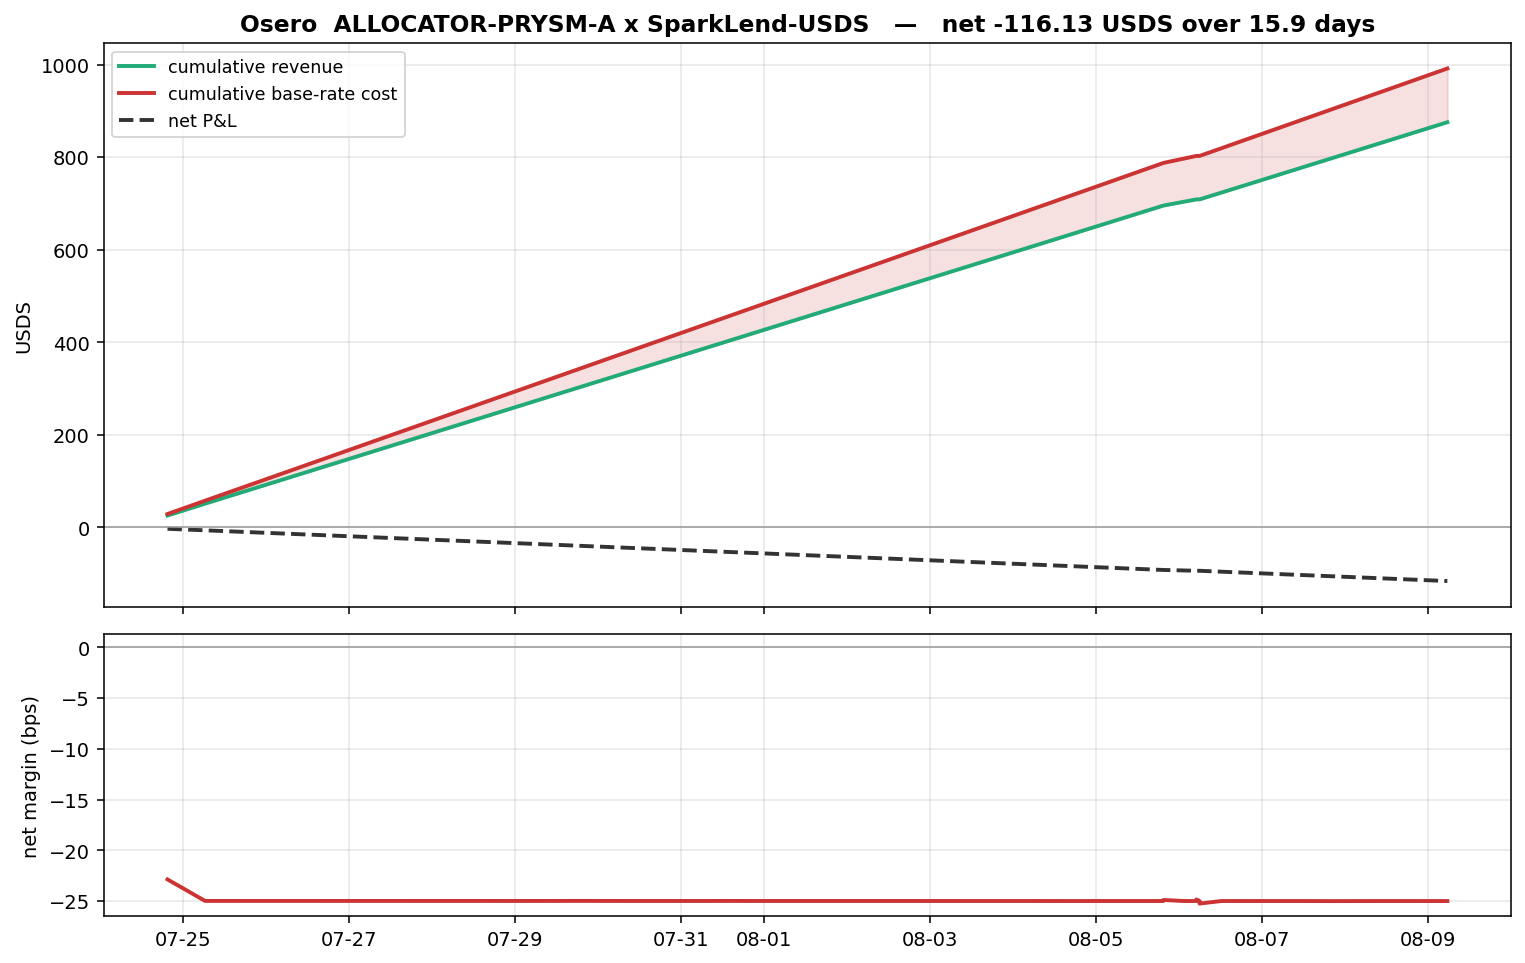

In [26]:
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

cum_r = cum_c = 0.0
curve = []
for a, b in zip(SERIES, SERIES[1:]):
    d = b["ts"] - a["ts"]
    cum_r += 0.5 * (a["position"] * a["supply_apr"] +
                    b["position"] * b["supply_apr"]) * d / SECONDS_PER_YEAR
    cum_c += 0.5 * (a["util"] * a["position"] * a["base"] +
                    b["util"] * b["position"] * b["base"]) * d / SECONDS_PER_YEAR
    curve.append((dt.datetime.utcfromtimestamp(b["ts"]), cum_r, cum_c, cum_r - cum_c,
                  (b["supply_apy"] - b["base"] * b["util"]) * 1e4))

x = [c[0] for c in curve]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, height_ratios=[2, 1])

ax1.plot(x, [c[1] for c in curve], color="#22aa77", lw=2, label="cumulative revenue")
ax1.plot(x, [c[2] for c in curve], color="#cc3333", lw=2, label="cumulative base-rate cost")
ax1.fill_between(x, [c[1] for c in curve], [c[2] for c in curve], color="#cc3333", alpha=.15)
ax1.plot(x, [c[3] for c in curve], color="#333333", lw=2, ls="--", label="net P&L")
ax1.axhline(0, color="#999999", lw=.8)
ax1.set_ylabel("USDS")
ax1.legend(fontsize=9, loc="upper left")
ax1.set_title(f"Osero  ALLOCATOR-PRYSM-A x SparkLend-USDS   —   "
              f"net {curve[-1][3]:+,.2f} USDS over {SPAN_DAYS:.1f} days",
              fontweight="bold")
ax1.grid(alpha=.3)

ax2.plot(x, [c[4] for c in curve], color="#cc3333", lw=2)
ax2.axhline(0, color="#999999", lw=.8)
ax2.set_ylabel("net margin (bps)")
ax2.grid(alpha=.3)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

plt.tight_layout()
IMAGES = HERE / "images"
IMAGES.mkdir(exist_ok=True)
out_path = IMAGES / "osero_pnl.png"
plt.savefig(out_path, dpi=140, bbox_inches="tight")
plt.show()
print(f"saved {out_path}")

The red band is the whole story: cost outruns revenue from the first block and the gap widens
monotonically. The kink is the idle window from Step 7. The lower panel never crosses zero.

## Step 13 — What would have to change?

Solve `supplyRate = baseRate × utilization` for each input, holding the others fixed.

In [27]:
be_ssr   = SUPPLY_APY / UTIL - SPREAD      # SSR that makes the margin zero
be_supply = BASE * UTIL                    # supply APY that would
be_util   = SUPPLY_APY / BASE              # utilization that would

print(f"  now:  supply {SUPPLY_APY:.4%}   base {BASE:.4%}   util {UTIL:.4%}"
      f"   -> {MARGIN_BPS:+.2f} bps\n")
print(f"  (a) SSR falls to          {be_ssr:>9.4%}   ({(be_ssr - SSR_APY) * 1e4:>+7.1f} bps)")
print(f"  (b) supply rate rises to  {be_supply:>9.4%}   ({(be_supply - SUPPLY_APY) * 1e4:>+7.1f} bps)")
print(f"  (c) utilization falls to  {be_util:>9.4%}   ({(be_util - UTIL) * 1e4:>+7.1f} bps)")

print("\n  consistency — recompute the margin at each break-even (should be 0):")
for lbl, rev, base, util in [("a", SUPPLY_APY, be_ssr + SPREAD, UTIL),
                             ("b", be_supply,  BASE,            UTIL),
                             ("c", SUPPLY_APY, BASE,            be_util)]:
    print(f"    ({lbl}) {(rev - base * util) * 1e4:>+.6f} bps")

  now:  supply 2.0560%   base 3.7200%   util 61.9850%   -> -24.99 bps

  (a) SSR falls to            3.1169%   (  -40.3 bps)
  (b) supply rate rises to    2.3058%   (  +25.0 bps)
  (c) utilization falls to   55.2677%   ( -671.7 bps)

  consistency — recompute the margin at each break-even (should be 0):
    (a) +0.000000 bps
    (b) +0.000000 bps
    (c) +0.000000 bps


Route (c) is a trap. Utilization isn't independent of the supply rate — they're coupled through the
reserve's interest-rate strategy, so falling utilization *lowers* the supply rate and the break-even
chases itself down. The rate-aware question is whether the borrow side can support the base rate at all.

In [28]:
BORROW_APR = word(reserve_data(), RD_BORROW_RATE) / RAY
RESERVE_FACTOR = 0.10          # Spark's cut of borrow interest

print(f"  borrowers pay              {BORROW_APR:>9.4%}")
print(f"  suppliers receive          {BORROW_APR * (1 - RESERVE_FACTOR):>9.4%}"
      f"   (net of ~{RESERVE_FACTOR:.0%} reserve factor, at 100% utilization)")
print(f"  Osero owes Sky             {BASE:>9.4%}")
print(f"  shortfall                  {(BORROW_APR * (1 - RESERVE_FACTOR) - BASE) * 1e4:>+8.1f} bps")

  borrowers pay                3.6485%
  suppliers receive            3.2836%   (net of ~10% reserve factor, at 100% utilization)
  Osero owes Sky               3.7200%
  shortfall                     -43.6 bps


**Even at 100% utilization** — every USDS in the reserve lent out, the theoretical maximum — the
supply side still wouldn't cover the base rate. The trade doesn't work at any utilization. It needs SSR
to fall, or Spark's borrow curve to reprice.

## Step 14 — The obvious objection: are we missing revenue?

A ~25 bps loss is the shape of a position whose real yield is somewhere we haven't looked. SparkLend
runs SPK campaigns, and a rewards stream would flip the sign.

In [29]:
INCENTIVES = addr_at(eth_call(ATOKEN, "getIncentivesController()"))
rewards_raw = eth_call(INCENTIVES, "getRewardsByAsset(address)", enc_addr(ATOKEN))
n_rewards = word(rewards_raw, 1)

print(f"incentives controller     {INCENTIVES}")
print(f"reward tokens on spUSDS   {n_rewards}")

incentives controller     0x4370d3b6c9588e02ce9d22e684387859c7ff5b34
reward tokens on spUSDS   0


Empty — no reward token is configured for this asset, so nothing accrues to *any* spUSDS holder.

More conclusive: Step 6 reconciled net principal against the debt exactly, and Step 7 showed
`USDS + spUSDS` conserved across the only window where capital left the venue. A third asset flowing
to the proxy would have broken one of those identities. There is no hidden revenue.

## The verdict

In [30]:
print(f"""
  Is Osero making money?                    NO

  position                       {POSITION:>14,.2f} USDS   in SparkLend USDS
  debt to Sky                    {DEBT:>14,.2f} USDS
  age                            {SPAN_DAYS:>14.2f} days

  revenue  supply {SUPPLY_APY:.4%}          {REALIZED_REVENUE:>+14,.2f} USDS
  cost     {BASE:.4%} x {UTIL:.2%} util  {-COST:>+14,.2f} USDS
  ---------------------------------------------------------
  net                            {NET:>+14,.2f} USDS
  current margin                 {MARGIN_BPS:>+14.2f} bps
  annualized run-rate            {(revenue_rate - cost_rate) * POSITION:>+14,.2f} USDS/yr
""")


  Is Osero making money?                    NO

  position                         1,001,874.83 USDS   in SparkLend USDS
  debt to Sky                      1,001,000.00 USDS
  age                                     15.88 days

  revenue  supply 2.0560%                 +874.83 USDS
  cost     3.7200% x 61.99% util         -991.50 USDS
  ---------------------------------------------------------
  net                                   -116.67 USDS
  current margin                         -24.99 bps
  annualized run-rate                 -2,503.52 USDS/yr


### What the number means

Osero draws from Sky at SSR + 20 bps and supplies into SparkLend — *also Sky* — at a supply rate below
that base. Both legs sit inside the same ecosystem and the spread between them is negative. Not a bad
entry: structural at current rates, and Step 13 shows it doesn't close at any reachable utilization.

Three readings, which the on-chain evidence doesn't distinguish:

- **A placeholder.** ~16 days old, fully withdrawn and redeposited mid-life — operationally active,
  not parked and forgotten. Capital may be staged pending a real strategy.
- **A rate view.** Works if SSR falls ~40 bps. SSR has moved repeatedly (6.25% → 3.52%) and is
  directionally falling.
- **Mispriced.** The 20 bps spread over SSR may exceed what a low-risk USDS venue can return now.

### Open questions

1. **Base-rate compounding is unspecified** — moves the answer ~4 bps (Step 10). Negligible over 16
   days, material over a year. Needs pinning with Sky.
2. **Utilization is market-wide, not Osero-specific.** A fungible pool has no per-lender utilization,
   so we apply the pool ratio. Defensible, worth confirming against Sky's own accounting.
3. **Does idle capital accrue base rate?** We say no, per the brief. The other reading makes the loss
   slightly larger.
4. **The sample is thin** — 16 days, one venue. The sign tracks the current spot spread rather than a
   long history, though that spread hasn't crossed zero once.

### Cross-checks

| Source | Span | Spot margin | Cumulative net |
|---|---|---|---|
| `discovery/` Python indexers (H-016) | ~11 days | −25.0 bps | ≈ −83 USDS |
| `osero-indexer/` Rust daemon, full backfill | ~11 days | −24.98 bps | −83.96 USDS |
| This notebook, block 25,715,376 | 15.9 days | −24.99 bps | −116.67 USDS |

Three independent implementations sharing no code agree on the spot margin to the basis point. The
cumulative figures differ only because they integrate to different head blocks — the position keeps
losing money as it ages, at roughly −7 USDS/day.